<a href="https://colab.research.google.com/github/suhanigupta786/Flight-Club/blob/main/07_AML_Model_Optimization_Calibration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 7 — AML Optimization, Calibration & Final Model Comparison
**Project 21: Flight Delay Prediction and Rescheduling** · AML portion only (no DL or rescheduling in this notebook).

**Input:** `task4_outputs.zip` from Task 4. Optionally `Task5_Logistic_Regression.zip` for the previously trained LR baseline. No 512 MB CSV required.

**Fair evaluation:** Jan–Aug training, Sep–Oct validation (chronologically separated into tuning / calibration / threshold slices), Nov–Dec **test once**. Compare Logistic Regression against optimized XGBoost using PR-AUC, ROC-AUC, Brier score, calibration curves, and recall at an operational precision requirement. The notebook will generate results; **no performance improvement is guaranteed**.

**Important:** The 24-hour prediction-time assumption and historical-feature availability must be justified separately; preprocessing artifacts alone cannot prove there is no leakage.

## 1. Setup and load Task 4 outputs
Upload `task4_outputs.zip` via the Colab Files sidebar. You may also upload `Task5_Logistic_Regression.zip`, but it is optional.

In [1]:
%pip -q install "xgboost>=2.0,<4" "scikit-learn>=1.3"

In [2]:
from pathlib import Path
import zipfile, shutil, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from scipy import sparse
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (precision_recall_curve, average_precision_score, roc_auc_score,
    brier_score_loss, log_loss, accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix)
from sklearn.calibration import calibration_curve
from xgboost import XGBClassifier
import xgboost

ROOT = Path('/content') if Path('/content').exists() else Path.cwd()
OUT = ROOT / 'task4_outputs'

def safe_extract(zip_file):
    with zipfile.ZipFile(zip_file) as z:
        for member in z.infolist():
            target = (ROOT / member.filename).resolve()
            if ROOT.resolve() not in target.parents and target != ROOT.resolve():
                raise ValueError('Unsafe ZIP path: ' + member.filename)
        z.extractall(ROOT)

if not OUT.is_dir():
    archive = ROOT / 'task4_outputs.zip'
    if not archive.exists():
        raise FileNotFoundError('Upload task4_outputs.zip into the Colab Files panel first.')
    safe_extract(archive)
assert OUT.is_dir(), 'ZIP must include task4_outputs/ folder'
print('XGBoost version:', xgboost.__version__)
print('Task 4 folder:', OUT)
print('Files:', sorted(p.name for p in OUT.iterdir()))

XGBoost version: 3.4.1
Task 4 folder: /content/task4_outputs
Files: ['X_test_cat_dl.npy', 'X_test_num_dl.npy', 'X_test_processed.npz', 'X_train_cat_dl.npy', 'X_train_num_dl.npy', 'X_train_processed.npz', 'X_val_cat_dl.npy', 'X_val_num_dl.npy', 'X_val_processed.npz', 'dl_preprocessing.joblib', 'preprocessor.joblib', 'processed_feature_names.csv', 'test_metadata.csv', 'train_metadata.csv', 'val_metadata.csv', 'y_test.npy', 'y_train.npy', 'y_val.npy']


In [3]:
def load_X(part):
    sp = OUT / f'X_{part}_processed.npz'
    dn = OUT / f'X_{part}_processed.npy'
    if sp.exists():
        return sparse.load_npz(sp).tocsr()
    if dn.exists():
        return np.load(dn, mmap_mode='r')
    raise FileNotFoundError(f'Missing feature matrix for {part}')

X_train, X_val, X_test = [load_X(s) for s in ['train','val','test']]
y_train, y_val, y_test = [np.load(OUT / f'y_{s}.npy').astype(int) for s in ['train','val','test']]
meta = {s: pd.read_csv(OUT / f'{s}_metadata.csv', parse_dates=['date']) for s in ['train','val','test']}
preprocessor = joblib.load(OUT / 'preprocessor.joblib')
feature_names = pd.read_csv(OUT / 'processed_feature_names.csv')['feature'].tolist()
expected = {'train':217727, 'val':55628, 'test':53991}
for s,X,y in zip(['train','val','test'],[X_train,X_val,X_test],[y_train,y_val,y_test]):
    assert X.shape[0] == len(y) == len(meta[s]) == expected[s], f'{s}: unexpected rows'
    assert X.shape[1] == len(feature_names)
    assert set(np.unique(y)).issubset({0,1})
    assert np.array_equal(y, meta[s]['delayed'].to_numpy(dtype=int))
    assert np.isfinite(X.data if sparse.issparse(X) else np.asarray(X)).all()
    print(s, 'rows',len(y),'features',X.shape[1], 'positive rate',round(y.mean(),4))
assert meta['train']['date'].max() < meta['val']['date'].min()
assert meta['val']['date'].max() < meta['test']['date'].min()
assert set(meta['train']['date'].dt.month.unique()) == set(range(1,9))
assert set(meta['val']['date'].dt.month.unique()) == {9,10}
assert set(meta['test']['date'].dt.month.unique()) == {11,12}
print('Chronological split / label / finite-value checks passed')

train rows 217727 features 356 positive rate 0.2561
val rows 55628 features 356 positive rate 0.1505
test rows 53991 features 356 positive rate 0.2499
Chronological split / label / finite-value checks passed


## 2. Partition validation chronologically
Use **Sep 1–24 for model selection/early stopping**, **Sep 25–Oct 12 for fitting calibrators**, and **Oct 13–31 for selecting operating thresholds**. Test data stays untouched until final evaluation. This reduces double-dipping, though the validation window remains limited.

In [4]:
dates = meta['val']['date']
idx_tune = np.where(dates < pd.Timestamp('2013-09-25'))[0]
idx_cal = np.where((dates >= pd.Timestamp('2013-09-25')) & (dates < pd.Timestamp('2013-10-13')))[0]
idx_threshold = np.where(dates >= pd.Timestamp('2013-10-13'))[0]
assert len(set(idx_tune)&set(idx_cal))==0 and len(set(idx_tune)&set(idx_threshold))==0
assert len(idx_tune)+len(idx_cal)+len(idx_threshold)==len(y_val)
assert all(len(i)>0 and len(np.unique(y_val[i]))==2 for i in [idx_tune,idx_cal,idx_threshold])
for name,idx in [('tuning',idx_tune),('calibration',idx_cal),('threshold selection',idx_threshold)]:
    print(name, len(idx), 'delay rate',round(y_val[idx].mean(),4))

tuning 21493 delay rate 0.1437
calibration 16465 delay rate 0.1465
threshold selection 17670 delay rate 0.1625


## 3. XGBoost hyperparameter search (validation only)
Three modest, CPU-friendly candidates. PR-AUC on the **tuning slice** decides the winner. Early stopping is computed on that same slice; this is model selection, not a final unbiased score.

In [5]:
class_ratio = float((y_train==0).sum() / max((y_train==1).sum(),1))
configs = [
    {'max_depth':3, 'learning_rate':0.05, 'min_child_weight':5, 'subsample':0.85, 'colsample_bytree':0.85},
    {'max_depth':5, 'learning_rate':0.05, 'min_child_weight':10, 'subsample':0.85, 'colsample_bytree':0.85},
    {'max_depth':4, 'learning_rate':0.03, 'min_child_weight':15, 'subsample':0.9, 'colsample_bytree':0.9},
]
search_rows=[]
best_score=-1
best_xgb=None
for i, params in enumerate(configs, start=1):
    candidate = XGBClassifier(
        n_estimators=650, objective='binary:logistic', eval_metric='aucpr',
        tree_method='hist', early_stopping_rounds=35, n_jobs=2, random_state=42,
        scale_pos_weight=class_ratio, **params)
    candidate.fit(X_train, y_train, eval_set=[(X_val[idx_tune],y_val[idx_tune])], verbose=False)
    p=candidate.predict_proba(X_val[idx_tune])[:,1]
    score=average_precision_score(y_val[idx_tune],p)
    row={'candidate':i, 'tuning_pr_auc':float(score), 'best_iteration':int(candidate.best_iteration), **params}
    search_rows.append(row)
    print('Candidate',i,'PR AUC',round(score,4),'best iteration',candidate.best_iteration)
    if score>best_score:
        best_score=score
        best_xgb=candidate
search_table=pd.DataFrame(search_rows).sort_values('tuning_pr_auc',ascending=False)
display(search_table)
print('Selected candidate:',int(search_table.iloc[0]['candidate']))

Candidate 1 PR AUC 0.2288 best iteration 101
Candidate 2 PR AUC 0.2273 best iteration 24
Candidate 3 PR AUC 0.2332 best iteration 101


,candidate,tuning_pr_auc,best_iteration,max_depth,learning_rate,min_child_weight,subsample,colsample_bytree
2,3,0.233161,101,4,0.03,15,0.90,0.90
0,1,0.228791,101,3,0.05,5,0.85,0.85
1,2,0.227284,24,5,0.05,10,0.85,0.85


Selected candidate: 3


## 4. Logistic Regression benchmark
If you upload the Task 5 ZIP, its saved model is used. Otherwise, the notebook retrains the **same Logistic Regression specification** on Task 4 features. It does **not** retrain imputation/encoding. Because your old Task 5 threshold was tuned for F1, both models receive **new**, comparable validation-only calibration and operating thresholds here.

In [7]:
lr_zip = ROOT / 'Task5_Logistic_Regression.zip'
lr_bundle_path = ROOT / 'task5_outputs' / 'logistic_regression_bundle.joblib'
if not lr_bundle_path.exists() and lr_zip.exists():
    safe_extract(lr_zip)
if lr_bundle_path.exists():
    lr_saved = joblib.load(lr_bundle_path)
    lr_model = lr_saved['model']
    print('Loaded trained Logistic Regression from Task 5 bundle')
else:
    lr_model = LogisticRegression(max_iter=2000, class_weight='balanced',random_state=42,solver='lbfgs')
    lr_model.fit(X_train,y_train)
    print('Trained equivalent Logistic Regression baseline (Task 5 bundle not provided)')
assert lr_model.predict_proba(X_val[idx_cal]).shape == (len(idx_cal),2)

Trained equivalent Logistic Regression baseline (Task 5 bundle not provided)


## 5. Probability calibration (Platt scaling)
We fit a *separate sigmoid calibrator* for each frozen model on the **calibration slice only**. It learns a logistic mapping from the raw log-odds score to observed delay probability. Compare raw vs calibrated reliability and Brier score; calibration does not necessarily improve every metric.

In [8]:
from scipy.special import logit

def fit_platt(model):
    raw=model.predict_proba(X_val[idx_cal])[:,1]
    score=logit(np.clip(raw,1e-6,1-1e-6)).reshape(-1,1)
    calibrator=LogisticRegression(C=1e3,solver='lbfgs',max_iter=1000)
    calibrator.fit(score,y_val[idx_cal])
    return calibrator

def calibrated_probability(model, cal, X):
    raw=model.predict_proba(X)[:,1]
    return cal.predict_proba(logit(np.clip(raw,1e-6,1-1e-6)).reshape(-1,1))[:,1]

models={'Logistic Regression':lr_model,'XGBoost tuned':best_xgb}
calibrators={name:fit_platt(m) for name,m in models.items()}
calibration_summary=[]
for name,m in models.items():
    raw=m.predict_proba(X_val[idx_threshold])[:,1]
    calibrated=calibrated_probability(m,calibrators[name],X_val[idx_threshold])
    for stage,p in [('uncalibrated',raw),('calibrated',calibrated)]:
        calibration_summary.append({'model':name,'probability':stage,
          'brier_score':brier_score_loss(y_val[idx_threshold],p),
          'pr_auc':average_precision_score(y_val[idx_threshold],p),
          'roc_auc':roc_auc_score(y_val[idx_threshold],p)})
display(pd.DataFrame(calibration_summary).round(4))

,model,probability,brier_score,pr_auc,roc_auc
0,Logistic Regression,uncalibrated,0.2200,0.2694,0.6455
1,Logistic Regression,calibrated,0.1309,0.2694,0.6455
2,XGBoost tuned,uncalibrated,0.2157,0.2963,0.6437
3,XGBoost tuned,calibrated,0.1304,0.2963,0.6437


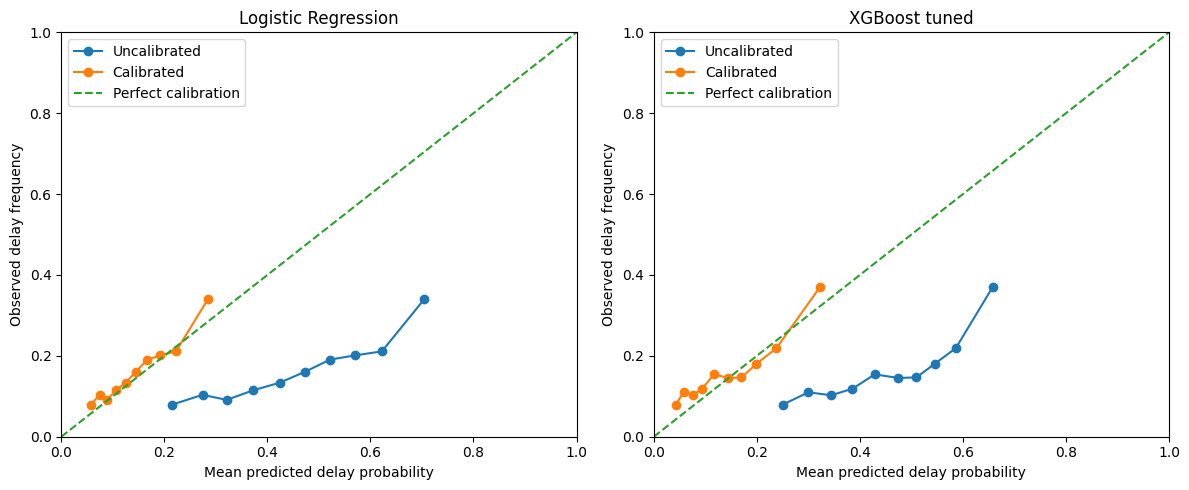

In [9]:
fig,axes=plt.subplots(1,2,figsize=(12,5))
for j,name in enumerate(models):
    ax=axes[j]
    m=models[name]
    raw=m.predict_proba(X_val[idx_threshold])[:,1]
    cal=calibrated_probability(m,calibrators[name],X_val[idx_threshold])
    for label,p in [('Uncalibrated',raw),('Calibrated',cal)]:
        observed,forecast=calibration_curve(y_val[idx_threshold],p,n_bins=10,strategy='quantile')
        ax.plot(forecast,observed,marker='o',label=label)
    ax.plot([0,1],[0,1],'--',label='Perfect calibration')
    ax.set(title=name,xlabel='Mean predicted delay probability',ylabel='Observed delay frequency',xlim=(0,1),ylim=(0,1))
    ax.legend()
plt.tight_layout()
plt.show()

## 6. Operational precision threshold
**Example operational policy:** require ≥ **35% precision** (at least 35 correct warnings per 100 delay alerts) on the last validation slice, and maximize recall subject to that condition. You may change this target *before* examining the test metrics. If no candidate reaches the chosen precision, the code reports this rather than silently lowering the requirement.

In [10]:
MIN_PRECISION = 0.35  # Operational assumption, not specified by the professor

def choose_threshold(y,p,min_precision):
    precision,recall,thresholds = precision_recall_curve(y,p)
    if len(thresholds)==0:
        raise ValueError('No usable prediction thresholds')
    valid=np.where(precision[:-1] >= min_precision)[0]
    if len(valid)==0:
        raise ValueError('No threshold meets operational precision target')
    # Highest recall; ties broken by larger precision then higher threshold
    rank=sorted(valid,key=lambda i:(-recall[i],-precision[i],-thresholds[i]))
    j=rank[0]
    return float(thresholds[j]),float(precision[j]),float(recall[j])

chosen={}
for name,m in models.items():
    p=calibrated_probability(m,calibrators[name],X_val[idx_threshold])
    try:
        th,prec,rec=choose_threshold(y_val[idx_threshold],p,MIN_PRECISION)
        chosen[name]=th
        print(f'{name}: threshold={th:.4f}, validation precision={prec:.4f}, validation recall={rec:.4f}')
    except ValueError as ex:
        chosen[name]=None
        print(name,':',ex)
if not any(v is not None for v in chosen.values()):
    raise ValueError('No model meets your specified precision target; report infeasibility or revise the operating policy before inspecting test results.')

Logistic Regression: threshold=0.2476, validation precision=0.3514, validation recall=0.1946
XGBoost tuned: threshold=0.2572, validation precision=0.3520, validation recall=0.2490


## 7. One-time held-out test evaluation
Everything above used training or validation only. We now evaluate the **untouched Nov–Dec test set**. Report PR-AUC, ROC-AUC, Brier score, recall at operational precision constraint, precision, F1 and confusion matrices. **Meeting the precision requirement on validation does not guarantee meeting it on test.**

In [11]:
def eval_metrics(name,y,p,threshold):
    pred=(p>=threshold).astype(int)
    tn,fp,fn,tp=confusion_matrix(y,pred,labels=[0,1]).ravel()
    return dict(model=name,threshold=threshold,n=len(y),positive_rate=float(y.mean()),
      accuracy=accuracy_score(y,pred),precision=precision_score(y,pred,zero_division=0),
      recall=recall_score(y,pred,zero_division=0), f1=f1_score(y,pred,zero_division=0),
      roc_auc=roc_auc_score(y,p),pr_auc=average_precision_score(y,p),
      brier_score=brier_score_loss(y,p),tn=int(tn),fp=int(fp),fn=int(fn),tp=int(tp))

test_rows=[]
for name,m in models.items():
    raw=m.predict_proba(X_test)[:,1]
    calibrated=calibrated_probability(m,calibrators[name],X_test)
    if chosen[name] is not None:
        test_rows.append(eval_metrics(name,y_test,calibrated,chosen[name]))
    else:
        print(name,': operational precision target not attainable on validation. No threshold-selected test result.')
    print(name,'uncalibrated test Brier:',round(brier_score_loss(y_test,raw),4),
          'calibrated test Brier:',round(brier_score_loss(y_test,calibrated),4))
results=pd.DataFrame(test_rows)
display(results.round(4))
print('No-change test delay prevalence (PR-AUC reference):',round(y_test.mean(),4))

Logistic Regression uncalibrated test Brier: 0.2193 calibrated test Brier: 0.1942
XGBoost tuned uncalibrated test Brier: 0.2174 calibrated test Brier: 0.1919


,model,threshold,n,positive_rate,accuracy,precision,recall,f1,roc_auc,pr_auc,brier_score,tn,fp,fn,tp
0,Logistic Regression,0.2476,53991,0.2499,0.7386,0.4121,0.1078,0.1709,0.6187,0.3387,0.1942,38425,2074,12038,1454
1,XGBoost tuned,0.2572,53991,0.2499,0.7351,0.4008,0.1215,0.1865,0.6392,0.3553,0.1919,38049,2450,11853,1639


No-change test delay prevalence (PR-AUC reference): 0.2499


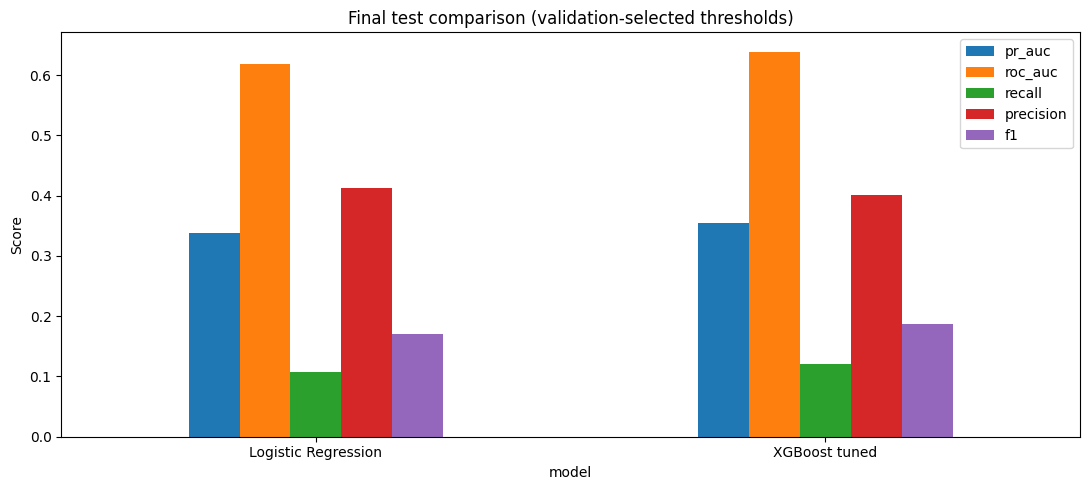

Logistic Regression Confusion matrix [[TN,FP],[FN,TP]]: [[38425, 2074], [12038, 1454]]
XGBoost tuned Confusion matrix [[TN,FP],[FN,TP]]: [[38049, 2450], [11853, 1639]]


In [12]:
if not results.empty:
    axes=results.plot(x='model',y=['pr_auc','roc_auc','recall','precision','f1'],kind='bar',figsize=(11,5),rot=0,title='Final test comparison (validation-selected thresholds)')
    axes.set_ylabel('Score')
    plt.tight_layout()
    plt.show()
    for row in results.to_dict('records'):
        print(row['model'], 'Confusion matrix [[TN,FP],[FN,TP]]:', [[row['tn'],row['fp']],[row['fn'],row['tp']]])

## 8. Save reproducible artifacts and final AML report
Saves the XGBoost model, both Platt calibrators, Logistic Regression baseline, validation-selected thresholds, metadata, and comparison files. The test predictions are **evaluation only**. Do not feed them back into tuning.

In [13]:
SAVE = ROOT / 'task7_outputs'
SAVE.mkdir(parents=True,exist_ok=True)
joblib.dump({'models':models,'calibrators':calibrators,'preprocessor':preprocessor,
             'feature_names':feature_names,'thresholds':chosen,
             'min_validation_precision':MIN_PRECISION,
             'time_definition':'24 hours before scheduled departure (assumed)',
             'chronological_splits':'train Jan-Aug 2013; val Sep-Oct; test Nov-Dec'},
            SAVE / 'aml_final_model_bundle.joblib')
search_table.to_csv(SAVE / 'xgboost_search.csv',index=False)
pd.DataFrame(calibration_summary).to_csv(SAVE / 'validation_calibration_metrics.csv',index=False)
results.to_csv(SAVE / 'final_test_comparison.csv',index=False)
with open(SAVE/'project_notes.txt','w') as f:
    f.write('Project 21 AML Task 7\n'
            'Split: Jan-Aug train, Sep-Oct validation, Nov-Dec test.\n'
            'Validation subdivisions: through Sep 24 tuning, Sep 25-Oct 12 calibration, Oct 13-31 thresholds.\n'
            f'Operational validation precision target: {MIN_PRECISION:.2f} (assumed policy, not assignment-specified).\n'
            'Models: Logistic Regression and XGBoost (PR-AUC selected).\n'
            'Calibrators: Platt scaling fitted to calibration-only validation slice.\n'
            'No DL or rescheduling included.\n'
            'Caution: historical feature availability must be verified for 24-hour predictions.\n')
print('Saved:',[p.name for p in SAVE.iterdir()])

Saved: ['validation_calibration_metrics.csv', 'aml_final_model_bundle.joblib', 'project_notes.txt', 'final_test_comparison.csv', 'xgboost_search.csv']


In [14]:
zip_file=shutil.make_archive(str(ROOT/'Task7_AML_Final_Evaluation'),'zip',root_dir=str(ROOT),base_dir='task7_outputs')
print('Download ready:',zip_file,'size MB:',round(Path(zip_file).stat().st_size/1024**2,2))
try:
    from google.colab import files
    files.download(zip_file)
except ImportError:
    print('Open the zip from your current folder:',zip_file)

Download ready: /content/Task7_AML_Final_Evaluation.zip size MB: 0.07


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Interpreting the results for your AML report
- **PR-AUC** is the central ranking metric under class imbalance; always compare it with the test positive rate.
- **Recall at operational precision** evaluates the chosen alerting tradeoff; report achieved test precision alongside recall and whether the validation target held.
- **Calibration / Brier score** evaluate probability reliability, not classification accuracy.
- Your model is **24-hour-ahead**, so avoid leakage from actual departure data. Historical features with day-level lag are only a conservative proxy for known information.
- Do not claim XGBoost beats Logistic Regression unless the final test comparison actually supports it. Keep your original Task 5–6 results as earlier baselines (their thresholds used different selection rules).